# Example of the aitlas toolbox in the context of semantic segmentation

This notebook shows a sample implementation of semantic segmentation using the aitlas toolbox. 

This notebook showcases an example with the Tangdaowan scene.

## Import the required packages

In [ ]:
from aitlas.datasets import QUHDataset
from aitlas.utils import image_loader
from aitlas.models import DeepLabV3
from aitlas.transforms import MinMaxNormTranspose, ResizeToTensor
import matplotlib.pyplot as plt
import numpy as np
import scipy.io

## Visualize images and masks

In [15]:
dataset_config = {
    "mat_file": "/home/dragik/data/FAIR_EO/QUH/QUH-Tangdaowan.mat"
}
dataset = QUHDataset(dataset_config)

print(f"Total number of patches: {len(dataset)}")

Total number of patches: 18


# Show images

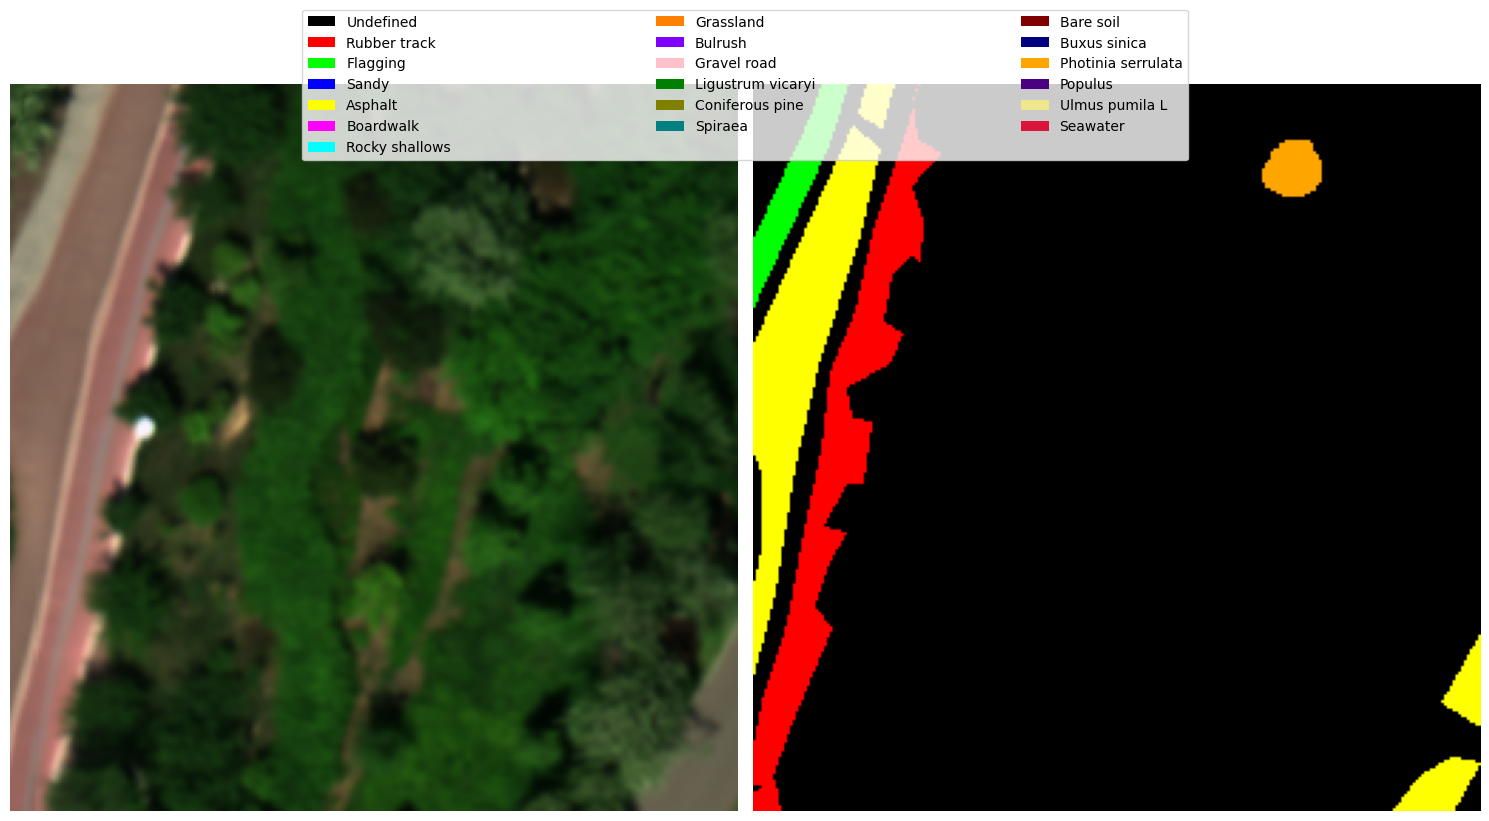

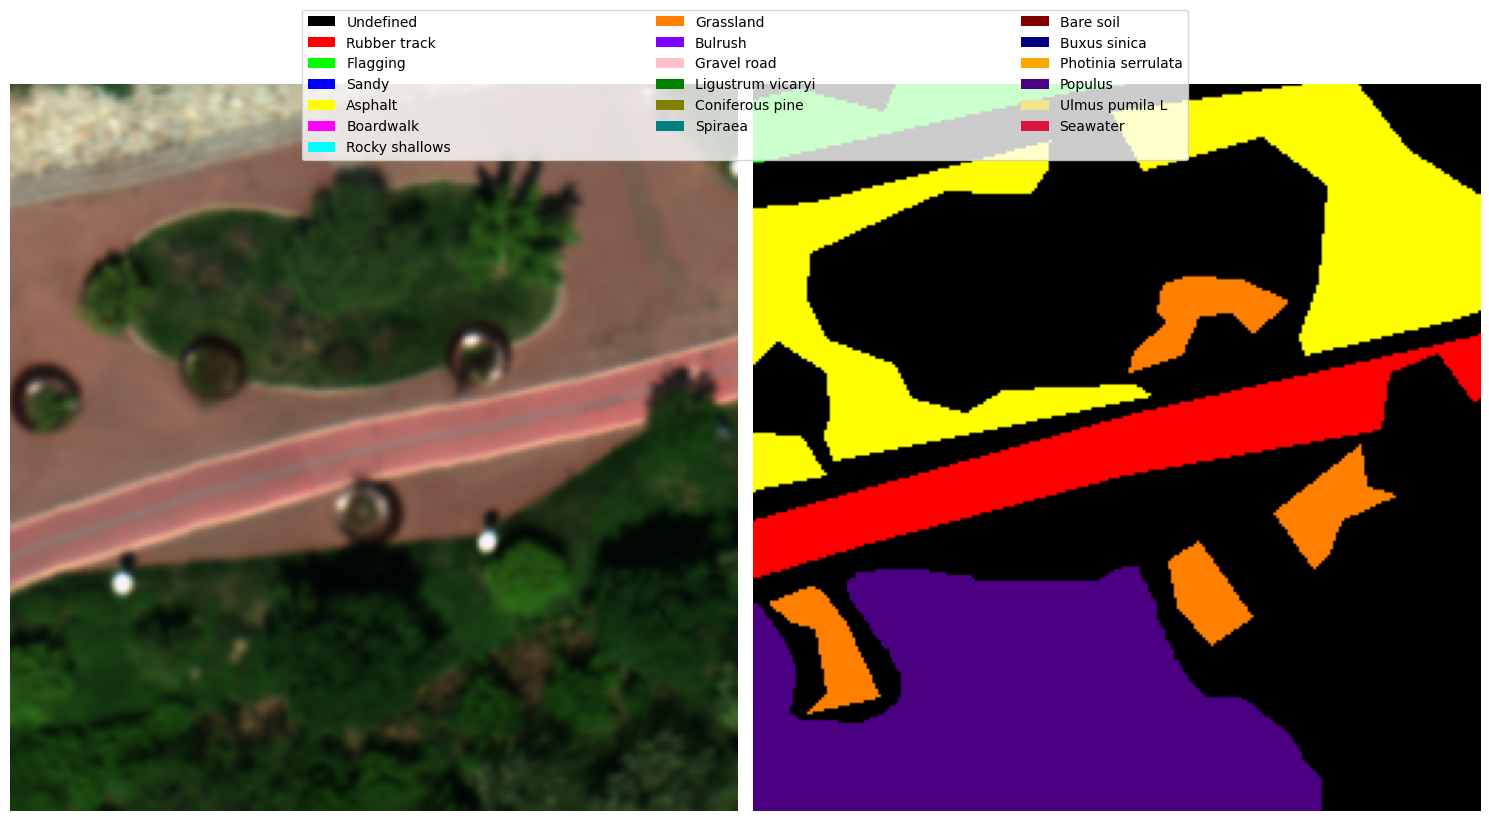

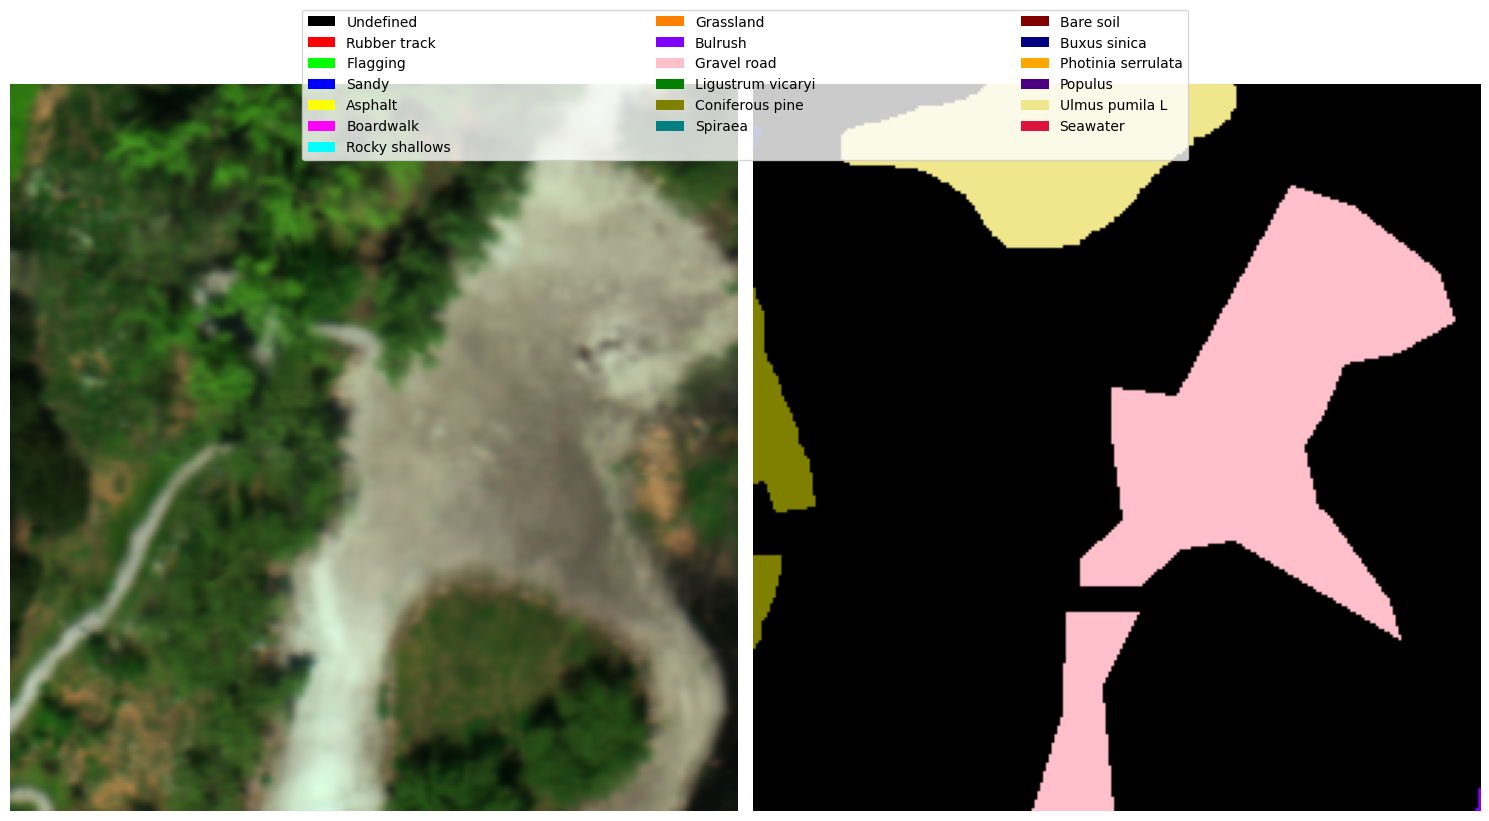

In [16]:
dataset.show_image(10)
dataset.show_image(2)
dataset.show_image(14);

In [17]:
dataset.data_distribution_table()

,Number of pixels
Undefined,939034
Rubber track,25849
Flagging,55553
Sandy,34037
Asphalt,60690
Boardwalk,1862
Rocky shallows,37125
Grassland,14127
Bulrush,64087
Gravel road,30695


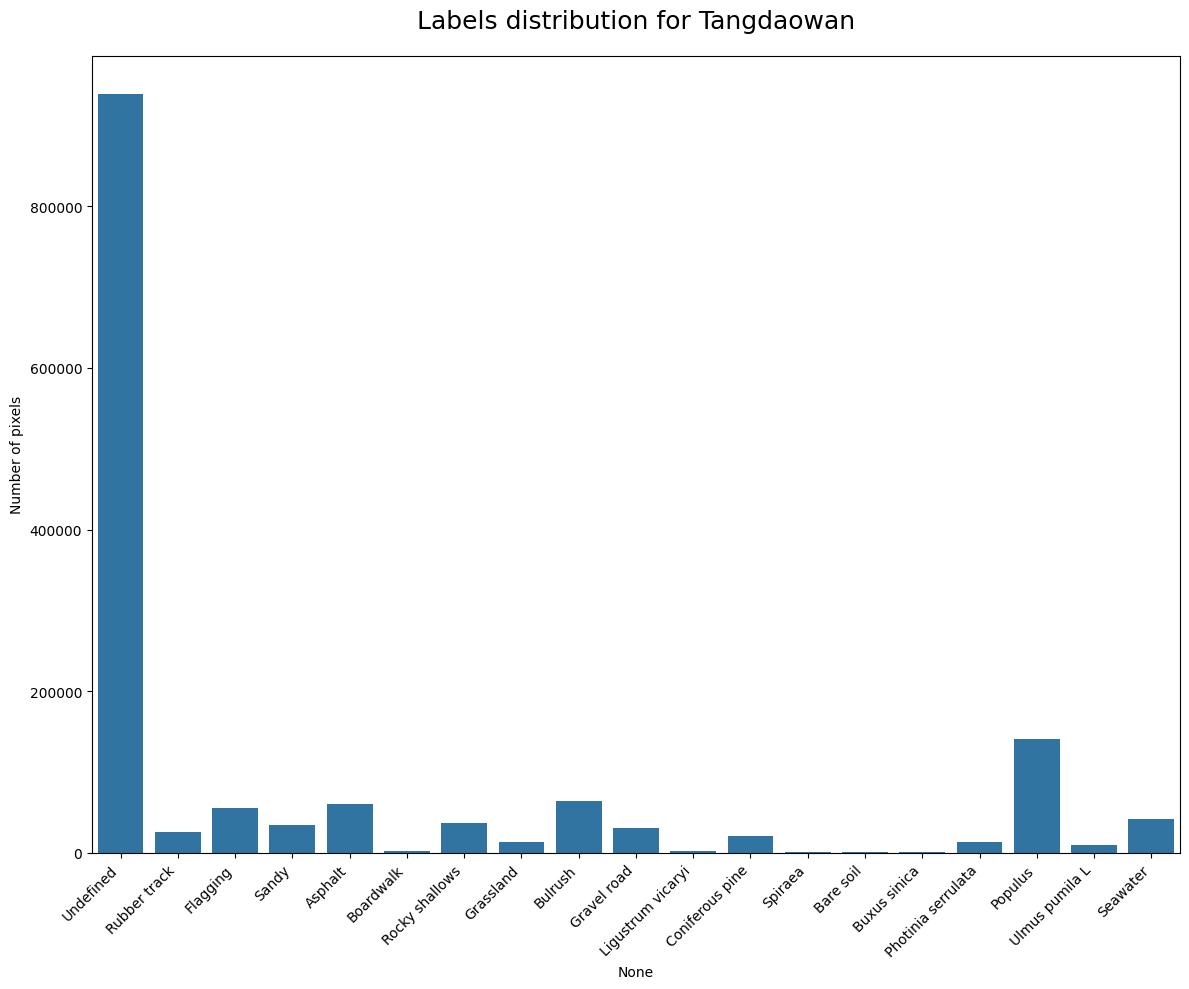

In [18]:
dataset.data_distribution_barchart();

## Load training data ##

In [36]:
train_dataset_config = {
    "batch_size": 4,
    "shuffle": True,
    "num_workers": 4,
    "mat_file": "/home/dragik/data/FAIR_EO/QUH/QUH-Tangdaowan.mat",
    "mode" : "train",
    "transforms": ["aitlas.transforms.MinMaxNormTranspose","aitlas.transforms.ResizeToTensor"],
    "target_transforms": ["aitlas.transforms.Transpose","aitlas.transforms.ResizePerChannelToTensor"]
}
train_dataset = QUHDataset(train_dataset_config)

len(train_dataset)

14

## Create the model ##

In [27]:
epochs = 20
model_directory = "/home/dragik/data/FAIR_EO/experiments/QUH"
model_config = {
    "num_classes": 19, 
    "learning_rate": 0.0001,
    "pretrained": True, 
    "threshold": 0.5,
    "metrics": ["iou"]
}

model = DeepLabV3(model_config)
model.prepare()

## Start the training ##

In [28]:
model.train_model(
    train_dataset=train_dataset,
    epochs=epochs,
    model_directory=model_directory,
    run_id='1'
)

2025-07-30 07:30:24,214 INFO Starting training.
training: 100%|██████████| 5/5 [00:54<00:00, 10.91s/it]
2025-07-30 07:31:18,859 INFO epoch: 1, time: 54, loss:  0.90672
testing on train set: 100%|██████████| 5/5 [00:54<00:00, 10.93s/it]
2025-07-30 07:32:15,472 INFO IOU:0.06494262828183925, IOU mean:0.043907576074879474, IOU per Class:[5.87707650e-01 2.00495871e-02 4.45649889e-02 0.00000000e+00
 4.48012931e-03 1.18849013e-03 5.55594189e-02 5.55284510e-03
 1.87174062e-02 0.00000000e+00 1.45382351e-03 3.05678723e-02
 6.34935167e-04 4.14134616e-03 4.80553835e-04 1.47305025e-02
 0.00000000e+00 8.30925836e-03 3.61051375e-02]
training: 100%|██████████| 5/5 [00:52<00:00, 10.47s/it]
2025-07-30 07:33:07,835 INFO epoch: 2, time: 52, loss:  0.90161
testing on train set: 100%|██████████| 5/5 [00:54<00:00, 10.94s/it]
2025-07-30 07:34:02,569 INFO IOU:0.01834449231318439, IOU mean:0.01991276366954581, IOU per Class:[0.01603416 0.01908144 0.04361553 0.         0.         0.00122075
 0.04093562 0.0056039

0.8497102128134834

## Evaluate the model

In [40]:
test_dataset_config = {
    "batch_size": 4,
    "shuffle": False,
    "num_workers": 4,
    "mat_file": "/home/dragik/data/FAIR_EO/QUH/QUH-Tangdaowan.mat",
    "mode": "val",
    "transforms": ["aitlas.transforms.MinMaxNormTranspose","aitlas.transforms.ResizeToTensor"], 
    "target_transforms": ["aitlas.transforms.Transpose","aitlas.transforms.ResizePerChannelToTensor"] 
}

test_dataset = QUHDataset(test_dataset_config)
print(len(test_dataset))

model = DeepLabV3(model_config)
model.prepare()
model.running_metrics.reset()
model_path = "/home/dragik/data/FAIR_EO/experiments/QUH/checkpoint.pth.tar"
model.evaluate(dataset=test_dataset, model_path=model_path)
model.running_metrics.get_scores(model.metrics)

2


2025-07-30 10:06:55,266 INFO Loading checkpoint /home/dragik/data/FAIR_EO/experiments/QUH/checkpoint.pth.tar
2025-07-30 10:06:55,651 INFO Loaded checkpoint /home/dragik/data/FAIR_EO/experiments/QUH/checkpoint.pth.tar at epoch 21
testing on test set: 100%|██████████| 1/1 [00:18<00:00, 18.45s/it]


[{'IOU': 0.025307040563844942,
  'IOU mean': 0.007499365943592661,
  'IOU per Class': array([0.06171555, 0.        , 0.        , 0.        , 0.        ,
         0.        , 0.        , 0.        , 0.        , 0.0807724 ,
         0.        , 0.        , 0.        , 0.        , 0.        ,
         0.        , 0.        , 0.        , 0.        ])}]

## Predictions

2025-07-30 10:47:30,818 INFO Loading checkpoint /home/dragik/data/FAIR_EO/experiments/QUH/checkpoint.pth.tar
2025-07-30 10:47:31,203 INFO Loaded checkpoint /home/dragik/data/FAIR_EO/experiments/QUH/checkpoint.pth.tar at epoch 21


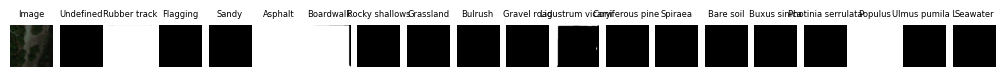

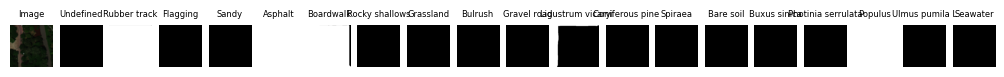

In [ ]:
model_path = "/home/dragik/data/FAIR_EO/experiments/QUH/checkpoint.pth.tar"
labels = ["Undefined", "Rubber track", "Flagging", "Sandy", "Asphalt", "Boardwalk", "Rocky shallows", 
          "Grassland", "Bulrush", "Gravel road","Ligustrum vicaryi", "Coniferous pine", "Spiraea", 
          "Bare soil", "Buxus sinica", "Photinia serrulata", "Populus", "Ulmus pumila L", "Seawater"]
IMG_H, IMG_W = 256, 256
transform = MinMaxNormTranspose()
model.load_model(model_path)
plt.rcParams.update({'font.size': 5})
mat = scipy.io.loadmat("/home/dragik/data/FAIR_EO/QUH/QUH-Tangdaowan.mat")
scene = mat['Tangdaowan']
height, width, _  = scene.shape
data = []
stride = IMG_H

for y in range(0, height - IMG_H + 1, stride):
    for x in range(0, width - IMG_W + 1, stride):
        if y + IMG_H <= height and x + IMG_W <= width:
            data.append((x,y))

for i in np.arange(3)[1 :]:
    x,y = data[-i]
    image = scene[y:y+IMG_H, x:x+IMG_W, [75, 45, 25]]
    fig = model.predict_masks(image, labels, transform)